# DNN - backtest

Forecasts are saved under `results/dnn/test/full/<model>.csv`.

Backtest of the DNN on the test set, every day of it (364 days). The model is the same as in `03_model_selection/02_DNN.ipynb`: the fully connected network from `epftoolbox` with two hidden layers, trained with the MAE loss, which forecasts all 24 hours of the next day at once. `calibration_window` is in years of 364 days, so `2` and `3` are the same history as LEAR's 728 and 1092 days.

The hyperparameters were tuned on the training set in `02_DNN.ipynb` (the trials files are in `data/dnn/hyperparameters/`) and are used here unchanged, so there is no tuning in this notebook. Every test day the network is retrained with them on the last `calibration_window` years, and a random quarter of the training weeks is held out for early stopping.

The model needs history before every test day, so the forecasts are made on `dataset_full`, the train, validation and test sets joined.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent.parent))

from src.config import EPF_EXOG
from src.utils.epf import evaluate_dnn, forecast_path
from src.utils.evaluation import compare_models, load_forecasts
from src.utils.file_io import load_final_dataset

/opt/homebrew/Caskroom/miniforge/base/envs/epf-lear-dnn/lib/python3.10/site-packages/hyperopt/atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
dataset_full = load_final_dataset("epf", "pl", "full")
dataset_test = load_final_dataset("epf", "pl", "test")
prices = dataset_full["PL_price"]

configs = [
    {"model": "DNN_2", "calibration_window": 2, "exog": EPF_EXOG},
    {"model": "DNN_3", "calibration_window": 3, "exog": EPF_EXOG},
]

test_start = dataset_test.index.min()
test_end = dataset_test.index.max()

## 1. Backtest

The tuned hyperparameters stay fixed. For each of the 364 test days the network is retrained on the last `calibration_window` years and forecasts the next 24 hours. A day that fails with an error during training is retried. The forecasts are saved to `results/dnn/test/full/<model>.csv`.

In [ ]:
for config in configs:
    evaluate_dnn(
        dataset=dataset_full,
        calibration_window=config["calibration_window"],
        exog=config["exog"],
        forecast_start=test_start,
        forecast_end=test_end,
        experiment_id=config["model"],
        path=forecast_path(config["model"], split="test", run="full", family="dnn"),
    )

## 2. Backtest comparison

Same metrics as for LEAR: MAE and RMSE in EUR/MWh, and rMAE relative to the weekly naive forecast. Lower is better for all three.

In [3]:
models = [config["model"] for config in configs]
forecasts = load_forecasts(
    [forecast_path(model, split="test", run="full", family="dnn") for model in models]
)

compare_models(
    forecasts,
    prices,
    metrics=["rMAE", "MAE", "RMSE", "sMAPE"],
)

,rMAE,MAE,RMSE,sMAPE
model,,,,
DNN_2,0.618667,22.944370,37.501518,0.287414
DNN_3,0.615529,22.827972,37.371745,0.283859


## 3. Error analysis

The error of an hour is the absolute difference from `PL_price`, and each point is the mean of those differences. `DNN_3` and `DNN_2` are drawn together.

In [4]:
from src.utils.plots import plot_heatmap, plot_lines, plot_weekday

MODELS = ["DNN_3", "DNN_2"]
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

aligned = prices.reindex(forecasts.index)
err = forecasts.rsub(aligned, axis=0).abs()[MODELS]
idx = err.index
by_hour = err.groupby(idx.hour).mean()
by_dow = err.groupby(idx.dayofweek).mean()
by_dow.index = DOW
by_month = err.groupby(idx.to_period("M")).mean()
by_month.index = by_month.index.astype(str)

### Hour

Each point is the mean absolute error of that hour over the test year.

In [5]:
by_hour.round(2)

,DNN_3,DNN_2
0,10.73,9.69
1,11.37,10.01
2,12.03,10.63
3,12.08,10.85
4,12.71,11.18
5,12.74,11.59
6,15.80,15.67
7,21.21,21.22
8,23.69,24.61
9,24.73,26.34


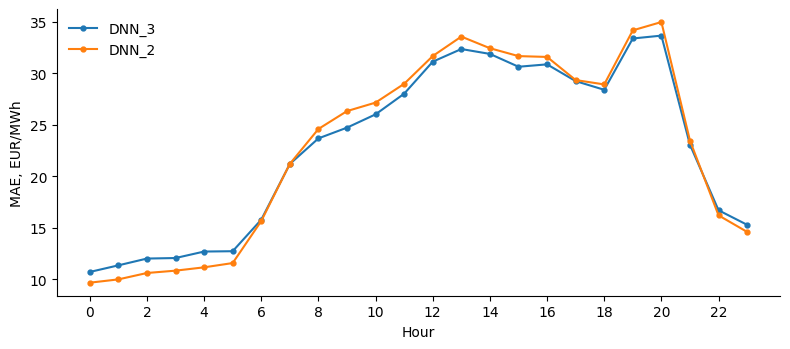

In [6]:
plot_lines(by_hour, xlabel="Hour", xticks=range(0, 24, 2))

### Weekday

In [7]:
by_dow.round(2)

,DNN_3,DNN_2
Mon,27.88,26.42
Tue,25.61,25.58
Wed,22.03,22.36
Thu,23.49,24.28
Fri,21.50,21.45
Sat,20.40,20.91
Sun,18.89,19.62


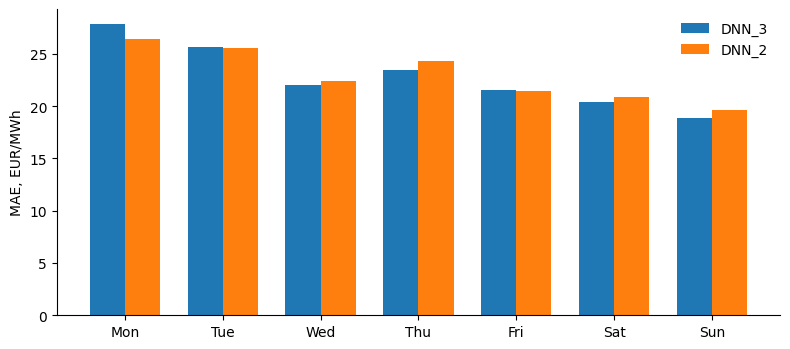

In [8]:
plot_weekday(by_dow)

### Month

Months run in chronological order. October 2025 starts on the 20th, and October 2026 ends on the 18th. The other months are complete.

In [9]:
by_month.round(2)

,DNN_3,DNN_2
2025-10,22.81,25.64
2025-11,20.63,20.81
2025-12,14.94,14.79
2026-01,30.80,30.29
2026-02,12.01,13.13
2026-03,20.56,20.71
2026-04,25.45,25.32
2026-05,19.33,19.61
2026-06,24.51,26.03
2026-07,20.85,20.48


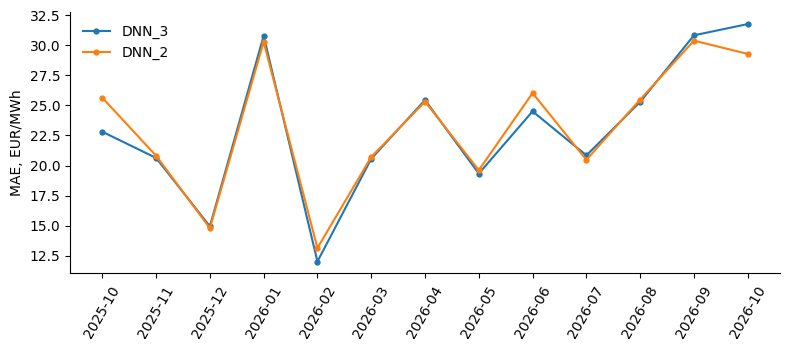

In [10]:
plot_lines(by_month, rotation=60)

### Hour by weekday

The two panels share one color scale.

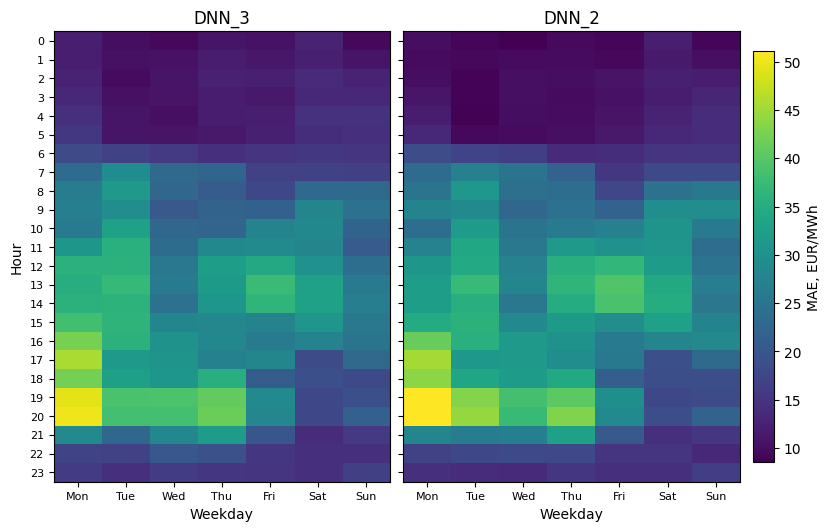

In [11]:
mats = []
for model in MODELS:
    mat = err[model].groupby([idx.hour, idx.dayofweek]).mean().unstack()
    mat.columns = DOW
    mats.append(mat)
plot_heatmap(mats, "Hour", "Weekday", MODELS)

### Weekday by month

The two panels share one color scale. The two Octobers are partial, and they are not the same month.

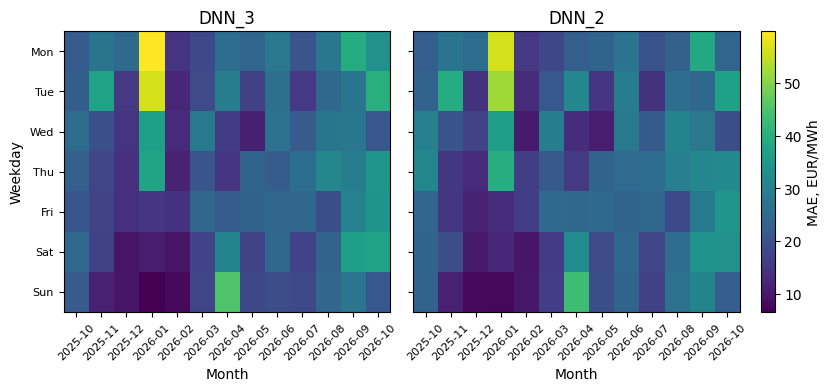

In [12]:
mats = []
for model in MODELS:
    mat = err[model].groupby([idx.dayofweek, idx.to_period("M")]).mean().unstack()
    mat.index = DOW
    mat.columns = mat.columns.astype(str)
    mats.append(mat)
plot_heatmap(mats, "Weekday", "Month", MODELS)